## 📈 A Season Break in the Recency Weights: Does It Improve the Forecasts?
### *(Backtest for the Football League Simulator's team ratings, October 2026)*

**Competitions:** Premier League, Championship, Serie A, La Liga, Bundesliga, Ligue 1, Eredivisie, and Primeira Liga\
**Question:** should last season's results count for less once a new season starts, instead of fading along one straight line?\
**Methods:** Poisson goal model, recency weighting, out-of-sample backtest with paired bootstrap confidence intervals\
**Author:** [Victoria Friss de Kereki](https://www.linkedin.com/in/victoria-friss-de-kereki/)\
**Live results (updated daily, all 9 leagues):** [football-league-simulator.streamlit.app](https://football-league-simulator.streamlit.app/)\
**Code:** [github.com/vickyfriss/football-league-predictions](https://github.com/vickyfriss/football-league-predictions)\
**Companion notebooks:** `202610 - 1 - Predicting Football League Positions (Masterclass Edition).ipynb`, `202610 - 3 - Market-Implied Team Strengths (Backtest).ipynb`\
**Last updated:** `26/10/2026`

### Why look at this?

Each team's attack and defence ratings come from goals scored and conceded in last season's and this season's league games, with recent games counting more. The weights run along **one straight line** across both seasons: the oldest game counts 1, the newest 2, rising a little with every game. There is no break at the summer, so the last games of last season count almost as much as this season's.

That shows up in the table. On 26 October 2026, Inter and Lazio were level on 22 points after 8 games, yet the simulator gave Inter a 71% title chance and Lazio 2%. Most of Lazio's rating still comes from 2025/26, when they finished on 54 points with 41 goals scored.

A summer break brings real change: transfers, new managers, promoted teams. So the obvious question is whether last season should count for less once the new one starts. This notebook tests two ways of doing that against the current straight line, using the production code itself.

### 1. Setup

Everything comes from the production repo, `football-league-predictions`, cloned next to this one. The function tested is the one that runs every morning: `compute_final_probabilities` in `3_probabilities.py`, which builds the ratings (including the early-season pull towards the league average and the promoted and relegated baselines) and blends in the market.

In [1]:
import importlib.util, io, os, contextlib, types, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson

warnings.filterwarnings("ignore")
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "football-league-predictions"))

def load_module(name, file):
    spec = importlib.util.spec_from_file_location(name, os.path.join(REPO, file))
    module = importlib.util.module_from_spec(spec)
    with contextlib.redirect_stdout(io.StringIO()):
        spec.loader.exec_module(module)
    return module

probabilities = load_module("probabilities", "3_probabilities.py")
processing = load_module("processing", "2_dataset_processing.py")

LEAGUES = ["premierleague_england", "championship_england", "seriea_italy", "laliga_spain",
           "bundesliga_germany", "ligue1_france", "eredivisie_netherlands", "primeiraliga_portugal"]
print("Production market weight:", probabilities.MARKET_WEIGHT)

Production market weight: 0.25


### 2. Data

* **Results:** football-data.org results for 2024/25, 2025/26 and 2026/27, with the same team-name mapping production applies.
* **Odds history:** the daily de-vigged bookmaker prices production keeps in `data/odds_history/`. They start in March 2026, so they only exist for the test season (section 5).

Brazil is left out, because its calendar-year season doesn't line up with the European ones. Primeira Liga has no 2024/25 results on file, so it only appears in the test season.

In [2]:
SEASON_START = {2025: pd.Timestamp("2025-07-15"), 2026: pd.Timestamp("2026-07-15")}

def season_of(date):
    return 2026 if date >= SEASON_START[2026] else 2025

_results = {}
def results(league, season):
    # season 2025 = 2025/26, as in the repo's file names
    if (league, season) not in _results:
        path = os.path.join(REPO, "data", f"past_{league}_{season}.csv")
        if not os.path.exists(path):
            df = pd.DataFrame(columns=["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals"])
        else:
            df = pd.read_csv(path)
            df = df[df["status"] == "FINISHED"].dropna(subset=["homeGoals", "awayGoals"])
            df = processing.normalize_columns(df).replace(processing.mappings.get(league, {}))
            df["utcDate"] = pd.to_datetime(df["utcDate"], utc=True).dt.tz_localize(None)
        _results[(league, season)] = df.sort_values("utcDate").reset_index(drop=True)
    return _results[(league, season)]

def load_odds_history(league):
    df = pd.read_csv(os.path.join(REPO, "data", "odds_history", f"{league}.csv"))
    df["snap_time"] = pd.to_datetime(df["snap_time"], utc=True).dt.tz_localize(None)
    df = df.rename(columns={"home_team": "homeTeam", "away_team": "awayTeam"})
    df[["homeTeam", "awayTeam"]] = df[["homeTeam", "awayTeam"]].replace(processing.mappings.get(league, {}))
    return df

odds = {lg: load_odds_history(lg) for lg in LEAGUES}
pd.DataFrame({lg: {s: len(results(lg, s)) for s in (2024, 2025, 2026)} for lg in LEAGUES}).T.rename(
    columns={2024: "2024/25 games", 2025: "2025/26 games", 2026: "2026/27 games so far"})

,2024/25 games,2025/26 games,2026/27 games so far
premierleague_england,380,380,80
championship_england,557,557,144
seriea_italy,380,380,80
laliga_spain,380,380,98
bundesliga_germany,305,306,63
ligue1_france,305,305,71
eredivisie_netherlands,306,306,90
primeiraliga_portugal,0,306,80


### 3. Swapping in other weights

Production sets the weights in one line, `df_all["weight"] = np.linspace(1, 2, len(df_all))`. To test alternatives without touching production, `recency()` swaps a different set of weights in at exactly that line and changes nothing else. Passing production's own straight line back in must reproduce production exactly, which the check below confirms.

The two alternatives each have one dial:

1. **Season discount.** Last season's games are multiplied by a fixed share (×1, ×0.75, ×0.5, ×0.35, ×0.25 or ×0.1), keeping a recency ramp by date across both seasons. ×1 is the straight line by date instead of by game, so it should score like production.
2. **Half-life by date.** A game's weight halves every N days (60 to 365). There are no games in the summer, so the gap between seasons discounts last season by itself.

In [3]:
class _NumpyWithWeights(types.ModuleType):
    # numpy as usual, except the one linspace(1, 2, n) call that sets the recency weights
    def __init__(self, weights):
        super().__init__("numpy"); self._weights = weights
    def __getattr__(self, attr):
        return getattr(np, attr)
    def linspace(self, start, stop, num, *args, **kwargs):
        if (start, stop) == (1, 2) and self._weights is not None and num == len(self._weights):
            return self._weights
        return np.linspace(start, stop, num, *args, **kwargs)

@contextlib.contextmanager
def recency(weights):
    probabilities.np = _NumpyWithWeights(weights)
    try:
        yield
    finally:
        probabilities.np = np

def scheme_weights(kind, value, dates, as_of):
    if kind == "line":
        return None  # production unchanged
    if kind == "discount":
        ramp = 1 + (dates - dates.min()) / (as_of - dates.min())
        return np.where(dates < SEASON_START[season_of(as_of)], value, 1.0) * ramp.to_numpy()
    if kind == "halflife":
        return 0.5 ** ((as_of - dates).dt.total_seconds().to_numpy() / 86400 / value)

SCHEMES = ([("line", None)] + [("discount", d) for d in (1.0, 0.75, 0.5, 0.35, 0.25, 0.1)]
           + [("halflife", h) for h in (60, 90, 120, 180, 270, 365)])
def scheme_name(kind, value):
    return "production line" if kind == "line" else f"last season ×{value:g}" if kind == "discount" else f"half-life {value} days"

def ratings_as_of(league, as_of, kind="line", value=None, use_market=False):
    season = season_of(as_of)
    current = results(league, season)
    current = current[current["utcDate"] < as_of]
    blended = pd.concat([results(league, season - 1), current], ignore_index=True).sort_values("utcDate", kind="stable").reset_index(drop=True)
    rosters = {lg: {s: set(pd.unique(results(lg, s)[["homeTeam", "awayTeam"]].values.ravel("K"))) for s in (season - 1, season)}
               for lg in {"premierleague_england", league}}
    with recency(scheme_weights(kind, value, blended["utcDate"], as_of)), contextlib.redirect_stdout(io.StringIO()):
        _, ratings, _ = probabilities.compute_final_probabilities(
            [league], {league: blended}, {league: pd.DataFrame({"homeTeam": ["placeholder"], "awayTeam": ["placeholder"]})}, {league: pd.DataFrame()},
            current_season_matches_dict={league: current}, prior_rosters_by_league_season=rosters,
            odds_history_dict={league: odds[league]} if use_market else None, as_of=as_of)
    return ratings[league], blended

D = pd.Timestamp("2026-10-20 10:00")
prod, blended = ratings_as_of("seriea_italy", D)
same = ratings_as_of("seriea_italy", D, "discount", 1.0)[0]  # not identical: by date, not by game
with recency(np.linspace(1, 2, len(blended))):
    check, _ = ratings_as_of("seriea_italy", D)
print("Production's own line passed back in reproduces production:",
      np.allclose(prod["attack_goals"].sort_index(), check["attack_goals"].sort_index()))

Production's own line passed back in reproduces production: True


Here is what each dial does to Serie A as of 20 October 2026: how much of a team's goal rating comes from this season's games, and what that does to Lazio's and Inter's attack ratings (1.00 is league average).

,share from 2026/27,Lazio attack,Inter attack
weighting,,,
production line,20%,1.00,1.65
last season ×0.75,26%,1.02,1.65
last season ×0.5,35%,1.05,1.66
last season ×0.25,52%,1.11,1.67
half-life 365 days,23%,1.01,1.65
half-life 120 days,41%,1.09,1.67


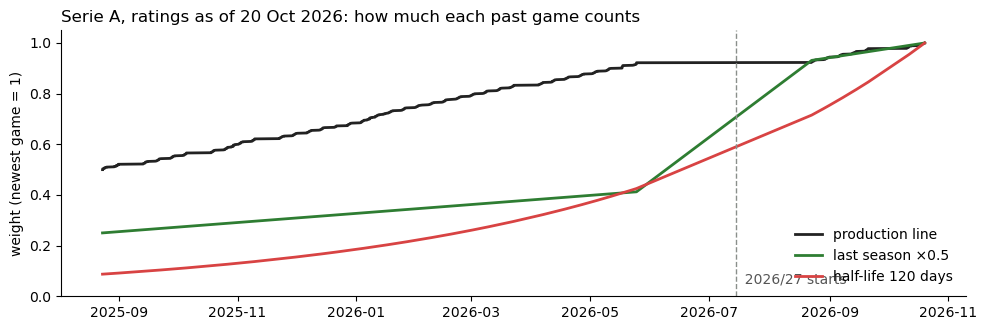

In [4]:
this_season = blended["utcDate"] >= SEASON_START[2026]
rows = []
for kind, value in [("line", None), ("discount", 0.75), ("discount", 0.5), ("discount", 0.25), ("halflife", 365), ("halflife", 120)]:
    w = scheme_weights(kind, value, blended["utcDate"], D)
    w = np.linspace(1, 2, len(blended)) if w is None else w
    r, _ = ratings_as_of("seriea_italy", D, kind, value)
    rows.append({"weighting": scheme_name(kind, value), "share from 2026/27": f"{w[this_season].sum() / w.sum():.0%}",
                 "Lazio attack": round(r["attack_goals"]["Lazio"], 2), "Inter attack": round(r["attack_goals"]["Internazionale"], 2)})
display(pd.DataFrame(rows).set_index("weighting"))

fig, ax = plt.subplots(figsize=(10, 3.4))
for kind, value, colour in [("line", None, "#222222"), ("discount", 0.5, "#2E7D32"), ("halflife", 120, "#D84343")]:
    w = scheme_weights(kind, value, blended["utcDate"], D)
    w = np.linspace(1, 2, len(blended)) if w is None else w
    ax.plot(blended["utcDate"], w / w[-1], label=scheme_name(kind, value), color=colour, lw=2)
ax.axvline(SEASON_START[2026], color="#8A8F8B", ls="--", lw=1); ax.text(SEASON_START[2026], 0.05, "  2026/27 starts", color="#555555")
ax.set_ylabel("weight (newest game = 1)"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, loc="lower right")
ax.set_title("Serie A, ratings as of 20 Oct 2026: how much each past game counts", loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

Under production, only about a fifth of the rating comes from this season. A strong discount or a short half-life flips that, and Lazio's attack rating rises with it. The question is whether that makes the forecasts **better**.

### 4. The backtest

* **Tuning season, 2025/26 (August 2025 to May 2026):** ratings rebuilt every Tuesday, using only what was known that day, with 2024/25 as "last season". Every match in the next four weeks is forecast and scored against the result. There are no odds yet for most of this season, so it is goals-only. Including the early weeks matters, because that's where a season break would make most difference.
* **Test season, 2026/27 (18 August to 20 October 2026):** the same, but with production's 25% market blend switched on, exactly as the dashboard runs.
* **Scored against the result** with the **Brier score** (squared gap between the three probabilities and what happened) and **log loss**; lower is better. In the test season, also against the **bookmakers' last price before kickoff** (RMSE), the best available estimate of the true probabilities.
* **Fair test:** the best setting is picked on 2025/26 only, then judged unchanged on 2026/27. Each match is forecast from up to four Tuesdays, so the confidence intervals resample whole matches.

In [5]:
_G = np.arange(7)  # 0-6 goals, the same grid as production's match_probabilities_league
def match_probs(r, home, away, market_weight):
    if market_weight > 0 and r["attack_market"] is not None:
        attack = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], market_weight)
        defence = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], market_weight)
    else:
        attack, defence = r["attack_goals"], r["defense_goals"]
    base = np.log(r["league_avg"])
    lam_h = np.exp(base + np.log(attack.reindex(home).fillna(1.0).to_numpy()) + np.log(defence.reindex(away).fillna(1.0).to_numpy()) + r["home_adv"])
    lam_a = np.exp(base + np.log(attack.reindex(away).fillna(1.0).to_numpy()) + np.log(defence.reindex(home).fillna(1.0).to_numpy()))
    grid = poisson.pmf(_G[None, :], lam_h[:, None])[:, :, None] * poisson.pmf(_G[None, :], lam_a[:, None])[:, None, :]
    lower = np.tril(np.ones((7, 7)), -1)
    p = np.stack([(grid * lower).sum((1, 2)), (grid * np.eye(7)).sum((1, 2)), (grid * lower.T).sum((1, 2))], 1)
    return p / p.sum(1, keepdims=True)

# same answer as production's own function
r = ratings_as_of("seriea_italy", D)[0]
p_fast = match_probs(r, pd.Index(["Lazio"]), pd.Index(["Internazionale"]), 0)[0]
p_prod = np.array(probabilities.match_probabilities_league("Lazio", "Internazionale", r["attack_goals"], r["defense_goals"], r["league_avg"], r["home_adv"]))
print("Matches production:", np.allclose(p_fast, p_prod / p_prod.sum()))

def backtest(season, dates, market_weight):
    rows = []
    for lg in LEAGUES:
        if results(lg, season - 1).empty:
            continue
        played = results(lg, season)
        for as_of in dates:
            if not (played["utcDate"] < as_of).any():
                continue
            targets = played[(played["utcDate"] >= as_of) & (played["utcDate"] < as_of + pd.Timedelta(days=28))]
            if targets.empty:
                continue
            y = np.where(targets["homeGoals"] > targets["awayGoals"], 0, np.where(targets["homeGoals"] == targets["awayGoals"], 1, 2))
            week = (as_of - played["utcDate"].min()).days // 7
            for kind, value in SCHEMES:
                r, _ = ratings_as_of(lg, as_of, kind, value, use_market=market_weight > 0)
                P = match_probs(r, targets["homeTeam"], targets["awayTeam"], market_weight)
                for i, m in enumerate(targets.itertuples()):
                    rows.append({"league": lg, "date": as_of, "week": week, "home": m.homeTeam, "away": m.awayTeam,
                                 "kickoff": m.utcDate, "scheme": scheme_name(kind, value), "y": y[i], "p": P[i]})
    df = pd.DataFrame(rows)
    P, Y = np.stack(df["p"]), np.eye(3)[df["y"]]
    df["Brier"] = ((P - Y) ** 2).sum(1)
    df["log loss"] = -np.log(np.clip(P[np.arange(len(df)), df["y"]], 1e-9, 1))
    df["match"] = df["league"] + "|" + df["home"] + "|" + df["away"]
    return df

tuning = backtest(2025, pd.date_range("2025-08-19 10:00", "2026-05-19 10:00", freq="7D"), 0.0)
test = backtest(2026, pd.date_range("2026-08-18 10:00", "2026-10-20 10:00", freq="7D"), probabilities.MARKET_WEIGHT)
for label, df in [("Tuning, 2025/26", tuning), ("Test, 2026/27", test)]:
    one = df[df["scheme"] == "production line"]
    print(f"{label}: {len(one):,} forecasts of {one['match'].nunique():,} matches")

Matches production: True


Tuning, 2025/26: 9,775 forecasts of 2,520 matches
Test, 2026/27: 1,988 forecasts of 616 matches


### 5. Results

In [6]:
order = [scheme_name(k, v) for k, v in SCHEMES]
table = pd.concat({label: df.groupby("scheme")[["Brier", "log loss"]].mean().reindex(order)
                   for label, df in [("Tuning 2025/26 (goals only)", tuning), ("Test 2026/27 (25% market)", test)]}, axis=1)
display(table.round(4).style.highlight_min(axis=0, color="#d7ecd9"))
best = tuning.groupby("scheme")["Brier"].mean().idxmin()
print("Best on the tuning season (lowest Brier):", best)

Best on the tuning season (lowest Brier): half-life 270 days


Everything near the straight line scores almost the same, and strong breaks score clearly **worse** in the tuning season: halving each game's weight every 60 days, or counting last season at ×0.1, costs 0.006 to 0.010 Brier. The confidence intervals below put the gentle settings against production:

In [7]:
def paired_ci(df, a, b="production line", metric="Brier", B=2000, seed=0):
    # mean of (a minus b), with a 95% interval that resamples whole matches
    x = df[df["scheme"] == a].reset_index(drop=True); z = df[df["scheme"] == b].reset_index(drop=True)
    d = (x[metric] - z[metric]).to_numpy(); g = pd.factorize(x["match"])[0]
    sums, counts = np.bincount(g, d), np.bincount(g); rng = np.random.default_rng(seed)
    boot = [sums[i].sum() / counts[i].sum() for i in (rng.integers(0, len(sums), len(sums)) for _ in range(B))]
    return d.mean(), *np.percentile(boot, [2.5, 97.5])

rows = []
for s in ["half-life 365 days", "half-life 270 days", "last season ×0.75", "last season ×0.5", "last season ×0.25", "half-life 120 days"]:
    row = {"weighting": s}
    for label, df in [("tuning", tuning), ("test", test)]:
        est, lo, hi = paired_ci(df, s)
        row[f"{label}: Brier vs production"] = f"{est:+.4f} ({lo:+.4f} to {hi:+.4f})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("weighting"))

,tuning: Brier vs production,test: Brier vs production
weighting,,
half-life 365 days,-0.0002 (-0.0008 to +0.0003),-0.0005 (-0.0010 to +0.0000)
half-life 270 days,-0.0003 (-0.0013 to +0.0007),-0.0004 (-0.0014 to +0.0006)
last season ×0.75,-0.0002 (-0.0009 to +0.0005),-0.0011 (-0.0024 to +0.0002)
last season ×0.5,+0.0002 (-0.0014 to +0.0018),-0.0017 (-0.0048 to +0.0013)
last season ×0.25,+0.0022 (-0.0007 to +0.0053),-0.0007 (-0.0072 to +0.0059)
half-life 120 days,+0.0017 (-0.0012 to +0.0047),+0.0007 (-0.0034 to +0.0047)


**No setting beats production by more than noise.** The setting picked on 2025/26 (a half-life of about a year, 270 or 365 days, which tie) improves the Brier score by 0.0002 to 0.0005 in each season, and every interval reaches zero. For scale, the 25% market blend improved it by 0.0079 on the same kind of test, more than ten times as much.

A discount of ×0.5 looks a little better on this season so far (-0.0017), but it wasn't the best on 2025/26 and its interval is wide (-0.0048 to +0.0013). Picking it because it wins on the test season would be fitting to noise.

### 6. Does it help early in the season?

A season break should matter most in the first weeks, when last season makes up most of the rating. Here is the Brier score of each weighting minus production's, by how far into the season the forecast was made:

In [8]:
cols = ["half-life 270 days", "last season ×0.75", "last season ×0.5", "last season ×0.25", "half-life 120 days"]
for label, df in [("Tuning, 2025/26", tuning), ("Test, 2026/27", test)]:
    df = df.assign(stage=pd.cut(df["week"], [-1, 7, 15, 25, 60], labels=["weeks 1-8", "weeks 9-16", "weeks 17-26", "weeks 27+"]))
    pivot = df.pivot_table(index="stage", columns="scheme", values="Brier", observed=True)
    out = pivot[cols].sub(pivot["production line"], axis=0).round(4)
    out["forecasts"] = df[df["scheme"] == "production line"].groupby("stage", observed=True).size()
    print(label); display(out)

Tuning, 2025/26


scheme,half-life 270 days,last season ×0.75,last season ×0.5,last season ×0.25,half-life 120 days,forecasts
stage,,,,,,
weeks 1-8,-0.0004,-0.0002,-0.0002,0.0017,-0.0007,1811
weeks 9-16,-0.0008,-0.0010,-0.0013,0.0000,0.0000,2077
weeks 17-26,-0.0005,0.0001,0.0010,0.0039,0.0019,2781
weeks 27+,0.0001,0.0000,0.0006,0.0024,0.0040,3106


Test, 2026/27


scheme,half-life 270 days,last season ×0.75,last season ×0.5,last season ×0.25,half-life 120 days,forecasts
stage,,,,,,
weeks 1-8,-0.0001,-0.0008,-0.0011,0.0003,0.0016,1791
weeks 9-16,-0.0026,-0.0034,-0.0069,-0.0101,-0.0073,197


Even in the first eight weeks, the differences stay within ±0.002. Stronger breaks look better in weeks 9 to 16 of this season, but that's only 197 forecasts from two Tuesdays, and the same weeks of 2025/26 (2,077 forecasts) show a gain of 0.0013 at most. The early-season pull towards the league average, which production already applies, seems to absorb most of what a season break would add. Strong breaks (×0.25, a 120-day half-life) are worse in the second half of 2025/26, when they throw away a full season of evidence for no gain.

### 7. Does it bring the forecasts closer to the bookmakers?

In the test season, each forecast compared with the bookmakers' last price before kickoff (lower is closer):

In [9]:
prices = pd.concat([o.assign(league=lg) for lg, o in odds.items()])
t = test.merge(prices, left_on=["league", "home", "away"], right_on=["league", "homeTeam", "awayTeam"])
t = t[t["snap_time"] < t["kickoff"]].sort_values("snap_time").groupby(["scheme", "league", "home", "away", "date"]).tail(1)
M = t[["p_home_book", "p_draw_book", "p_away_book"]].to_numpy()
t["sq"] = ((np.stack(t["p"]) - M) ** 2).mean(1)
rmse = t.groupby("scheme")["sq"].mean().pow(0.5).reindex(order).round(4).rename("RMSE vs bookmakers")
display(rmse.to_frame())
base = t[t["scheme"] == "production line"]
print(f"{base['match'].nunique()} priced matches. Brier on them: bookmakers {((M[(t['scheme'] == 'production line').to_numpy()] - np.eye(3)[base['y']]) ** 2).sum(1).mean():.4f}, "
      f"production {base['Brier'].mean():.4f}")

,RMSE vs bookmakers
scheme,
production line,0.0704
last season ×1,0.0701
last season ×0.75,0.0697
last season ×0.5,0.0702
last season ×0.35,0.0724
last season ×0.25,0.0763
last season ×0.1,0.0942
half-life 60 days,0.0896
half-life 90 days,0.0776


616 priced matches. Brier on them: bookmakers 0.5920, production 0.6137


The same picture. Gentle discounts move the forecasts very slightly towards the bookmakers (an RMSE of 0.0697 to 0.0701 against production's 0.0704), and strong ones move them clearly away (0.076 to 0.094). The bookmakers themselves still score about 0.02 Brier better than the model, and no recency setting closes a meaningful part of that gap.

### 8. Final thoughts

**A season break doesn't improve the forecasts.** Over a full season of tuning and the first ten weeks of this one, no alternative to the straight line beats it by more than noise, against the results or against the bookmakers.

* **Gentle breaks are harmless but add nothing.** A half-life of about a year, or counting last season at ×0.75, is a hair better in both seasons (0.0002 to 0.0011 Brier), well inside the noise.
* **Strong breaks make things worse.** Counting last season at ×0.25 or less, or halving a game's weight every 60 to 120 days, throws away evidence the model needs.
* **The early-season pull towards the league average already does the job** a season break was meant to do, and the 25% market blend brings in transfers and new managers faster than goals ever could.

So production stays as it is. For Lazio, the test says the model is right to keep trusting last season: after 8 games, a full season of evidence still says more about a team than a hot start.

**What this doesn't cover:**
* **Final positions.** This scores match forecasts, not full-season final positions; a title race depends on the same match forecasts, so a big change there is unlikely.
* **One test season.** The 2026/27 sample is ten weeks (about 2,000 forecasts). Rerunning this at the end of the season would cover the second half of a season with the market blend on.